In [1]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2




r_seed = 42

WORKDIR = 'C:/Users/thewr/git/LSTM_giroscopio_acelerometro.git/'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/"+data_hora

C:\Users\thewr\AppData\Local\Temp\ipykernel_34876\3432078421.py:15: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import RandomSearch
c:\Users\thewr\git\LSTM_giroscopio_acelerometro.git\.venv\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


In [2]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [3]:
## get dataset

# select only sensor data from smart watches
data = pd.read_csv('normalizado.csv')

In [4]:
data.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426757696641,4.972757,-0.158317,6.696732,0.314944,-1.022277,-0.309962
1,1600,0,90426807196641,3.253720,-0.191835,6.107758,0.387382,-0.618541,-0.048972
2,1600,0,90426856696641,2.801216,-0.155922,5.997625,0.070999,-0.209480,-0.195978
3,1600,0,90426906196641,3.770868,-1.051354,7.731027,0.037975,0.254976,-0.156563
4,1600,0,90426955696641,4.661511,0.169689,9.684695,0.073129,0.719431,-0.001035


In [5]:
data.isnull().sum()

pessoa_x          0
atividade         0
tempo             0
acelerômetro_x    0
acelerômetro_Y    0
acelerômetro_Z    0
giroscópio_x      0
giroscópio_Y      0
giroscópio_Z      0
dtype: int64

In [6]:
#remove the null class
data=data.dropna()

# **Data Exploration**

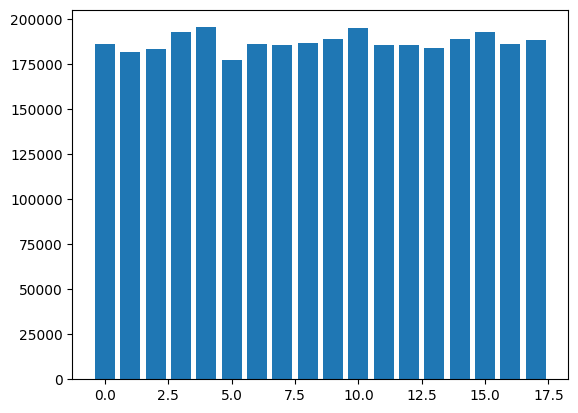

In [7]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

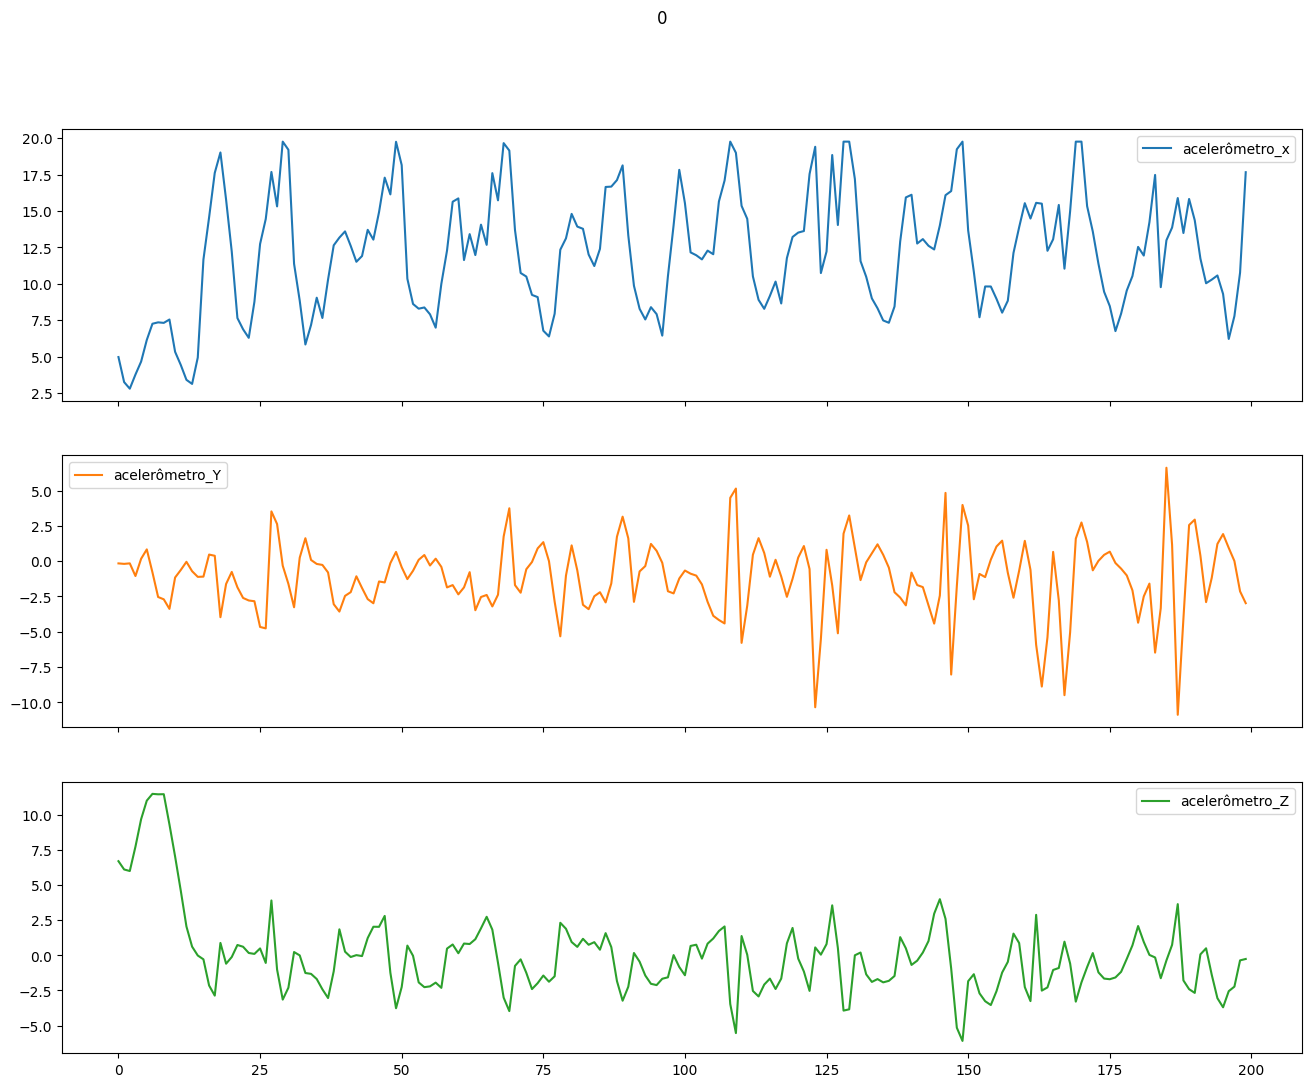

In [8]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

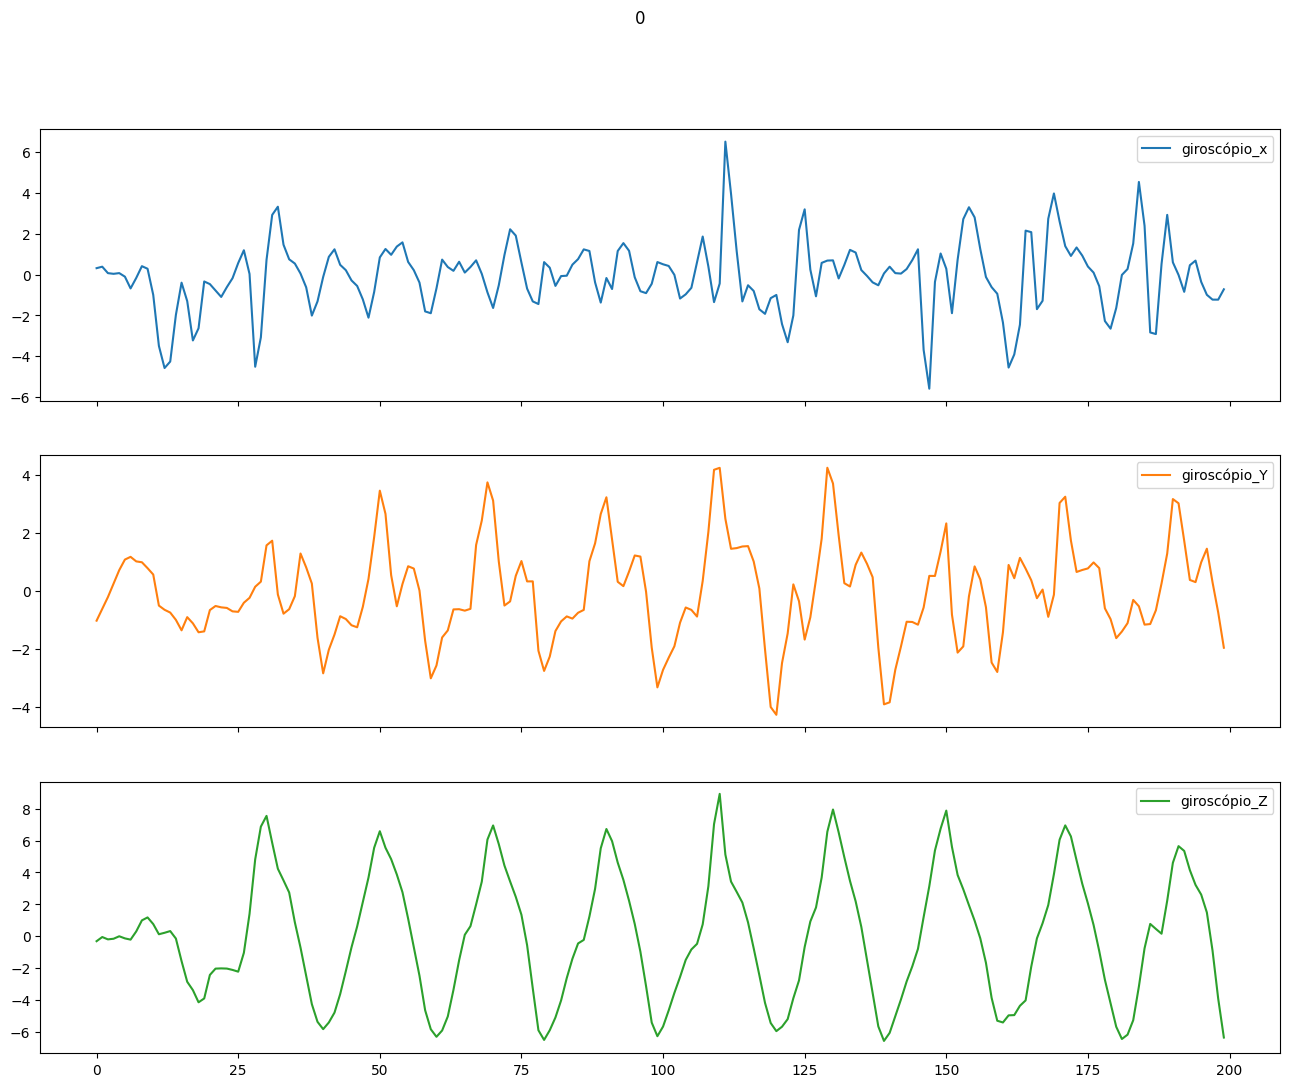

In [9]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['giroscópio_x','giroscópio_Y','giroscópio_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

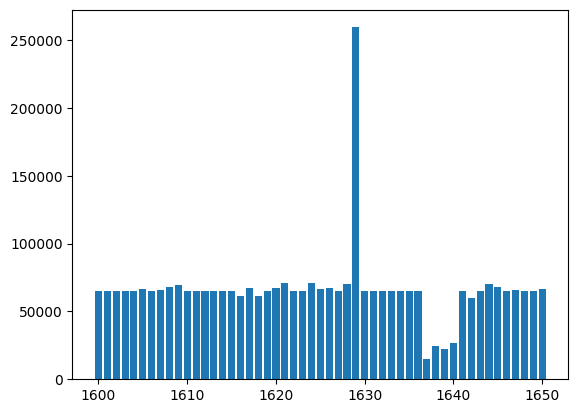

In [10]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [11]:
#selecting only activities 0 to 3
data = data[data["atividade"].isin([0,1,2,3,4,16])]

In [12]:
# Define the mapping dictionary
mapping_dict = {16: 5}

In [13]:
data["atividade"] = data["atividade"].replace(to_replace=mapping_dict)

In [14]:
data.shape

(1124770, 9)

In [15]:
data.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426757696641,4.972757,-0.158317,6.696732,0.314944,-1.022277,-0.309962
1,1600,0,90426807196641,3.253720,-0.191835,6.107758,0.387382,-0.618541,-0.048972
2,1600,0,90426856696641,2.801216,-0.155922,5.997625,0.070999,-0.209480,-0.195978
3,1600,0,90426906196641,3.770868,-1.051354,7.731027,0.037975,0.254976,-0.156563
4,1600,0,90426955696641,4.661511,0.169689,9.684695,0.073129,0.719431,-0.001035


In [16]:
data = data.reset_index()

In [17]:
data.head()

,index,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,0,1600,0,90426757696641,4.972757,-0.158317,6.696732,0.314944,-1.022277,-0.309962
1,1,1600,0,90426807196641,3.253720,-0.191835,6.107758,0.387382,-0.618541,-0.048972
2,2,1600,0,90426856696641,2.801216,-0.155922,5.997625,0.070999,-0.209480,-0.195978
3,3,1600,0,90426906196641,3.770868,-1.051354,7.731027,0.037975,0.254976,-0.156563
4,4,1600,0,90426955696641,4.661511,0.169689,9.684695,0.073129,0.719431,-0.001035


# **Models**

In [18]:
index_split_test_and_validation_train = data[(data['pessoa_x'].isin([1600,1601,1602,1603,1604]))].tail(1).index[0]
print(index_split_test_and_validation_train)

108176


In [19]:
#Will be used in model training and validation (approx. 90%)
train_validation_indices = []
#Will be used in final test of the model after training (approx. 10%)
test_indices = []


train_validation_indices.extend(data.index[index_split_test_and_validation_train+1:])
test_indices.extend(data.index[:index_split_test_and_validation_train+1])

# Split the dataset without shuffling
print(len(train_validation_indices))
print(len(test_indices))
X_train_validation = data.iloc[train_validation_indices]
X_test = data.iloc[test_indices]


# Print shapes to verify proportions
print("Train/validation set:", X_train_validation.shape)
print("Test set:", X_test.shape)

1016593
108177
Train/validation set: (1016593, 10)
Test set: (108177, 10)


In [20]:
X_test.head()

,index,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,0,1600,0,90426757696641,4.972757,-0.158317,6.696732,0.314944,-1.022277,-0.309962
1,1,1600,0,90426807196641,3.253720,-0.191835,6.107758,0.387382,-0.618541,-0.048972
2,2,1600,0,90426856696641,2.801216,-0.155922,5.997625,0.070999,-0.209480,-0.195978
3,3,1600,0,90426906196641,3.770868,-1.051354,7.731027,0.037975,0.254976,-0.156563
4,4,1600,0,90426955696641,4.661511,0.169689,9.684695,0.073129,0.719431,-0.001035


In [21]:
X_test.tail()

,index,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
108172,321325,1604,5,693765124458473,-2.013972,6.694038,9.212589,0.258029,-0.059641,0.195807
108173,321326,1604,5,693765174386733,-1.884686,6.832902,10.711359,0.023671,0.137433,0.119107
108174,321327,1604,5,693765224314993,-1.530344,6.454618,9.758467,0.205831,0.664739,-0.163188
108175,321328,1604,5,693765274243253,-2.107346,2.983026,9.411307,0.968561,1.264482,-0.037486
108176,321329,1604,5,693765324171513,-3.424157,5.192874,8.039430,0.868426,1.975014,-0.269714


In [22]:
X_train_validation.head()

,index,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
108177,324933,1605,0,9914136743005,6.753594,-4.764910,0.682347,-1.067869,0.084463,-0.797466
108178,324934,1605,0,9914186746890,7.301866,-4.116082,0.744597,-0.999692,-0.145634,-0.726093
108179,324935,1605,0,9914236752414,7.610718,-3.840749,1.113304,-0.604479,-0.177592,-0.636611
108180,324936,1605,0,9914286674776,8.999355,-3.986795,1.070208,-0.552281,-0.256422,-0.509845
108181,324937,1605,0,9914336690902,10.996120,-3.754557,0.720655,-0.495822,-0.227660,-0.465104


In [23]:
X_train_validation.tail()

,index,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
1124765,3364938,1650,5,2426615239501548,-2.564489,-7.467665,6.044761,-0.431518,0.265332,-0.145290
1124766,3364939,1650,5,2426615289493068,-2.698564,-9.500342,1.598728,-0.377189,0.679719,-0.153812
1124767,3364940,1650,5,2426615339484588,-2.940379,-7.946505,5.817312,-0.399560,1.495712,-0.118658
1124768,3364941,1650,5,2426615389476108,-4.329016,-8.466047,0.557250,-0.048023,0.742570,-0.111201
1124769,3364942,1650,5,2426615439467628,-5.267543,-8.664765,1.799841,0.429216,-1.566923,0.133809


In [24]:
X_test = X_test.reset_index(drop=True)

In [25]:
X_test = X_test.drop('index',axis=1)


In [26]:
X_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108177 entries, 0 to 108176
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   pessoa_x        108177 non-null  int64  
 1   atividade       108177 non-null  int64  
 2   tempo           108177 non-null  int64  
 3   acelerômetro_x  108177 non-null  float64
 4   acelerômetro_Y  108177 non-null  float64
 5   acelerômetro_Z  108177 non-null  float64
 6   giroscópio_x    108177 non-null  float64
 7   giroscópio_Y    108177 non-null  float64
 8   giroscópio_Z    108177 non-null  float64
dtypes: float64(6), int64(3)
memory usage: 7.4 MB


In [27]:
X_test['atividade'].value_counts()

atividade
4    18109
1    18014
2    18014
3    18014
0    18013
5    18013
Name: count, dtype: int64

In [28]:
X_test = X_test[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]

In [29]:
print(X_test.shape)

(108177, 7)


In [30]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [31]:
def apply_segmentation_no_sliding_window(df_data):
# Define window size and step size
    window_size = 200
    step_size = 20

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using sliding window
    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        #populate the 3d array only if the 200 segment has the value in label
        label_consistency = (df_data[['atividade']][start_idx:end_idx].nunique()==1) 
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [32]:
def apply_segmentation_with_sliding_window(df_data):
    #creating sliding window for train data
    import numpy as np

    window_size = 200
    step_size = 20

    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_size
        label_consistency = df_data[['atividade']][start_idx:end_idx].nunique()==1
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [33]:
segments_test,targets_test = apply_segmentation_no_sliding_window(X_test)

In [34]:
print(segments_test.shape)
print(targets_test.shape)

(540, 200, 6)
(540, 200, 1)


In [35]:
segments_test,targets_test = delete_segments_not_fully_filled(segments_test,targets_test)

In [36]:
print(segments_test.shape)
print(targets_test.shape)

(511, 200, 6)
(511, 200, 1)


In [37]:
print(segments_test.shape[0])

511


In [38]:
targets_test = targets_test.reshape(targets_test.shape[0],200)

In [39]:
print(targets_test.shape)

(511, 200)


In [40]:
labels_test = targets_test[:,0]

In [41]:
print(labels_test.shape)

(511,)


In [42]:
labels_test_categorical = to_categorical(labels_test,num_classes=6)

In [43]:
print(labels_test_categorical)

[[1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]]


In [44]:
print(labels_test_categorical.shape)

(511, 6)


In [45]:
X_train_validation = X_train_validation.reset_index(drop=True)
X_train_validation = X_train_validation.drop('index',axis=1)

In [46]:
X_train_validation.shape

(1016593, 9)

In [47]:
X_train_validation.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1605,0,9914136743005,6.753594,-4.764910,0.682347,-1.067869,0.084463,-0.797466
1,1605,0,9914186746890,7.301866,-4.116082,0.744597,-0.999692,-0.145634,-0.726093
2,1605,0,9914236752414,7.610718,-3.840749,1.113304,-0.604479,-0.177592,-0.636611
3,1605,0,9914286674776,8.999355,-3.986795,1.070208,-0.552281,-0.256422,-0.509845
4,1605,0,9914336690902,10.996120,-3.754557,0.720655,-0.495822,-0.227660,-0.465104


In [48]:
X_train_validation.tail()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
1016588,1650,5,2426615239501548,-2.564489,-7.467665,6.044761,-0.431518,0.265332,-0.145290
1016589,1650,5,2426615289493068,-2.698564,-9.500342,1.598728,-0.377189,0.679719,-0.153812
1016590,1650,5,2426615339484588,-2.940379,-7.946505,5.817312,-0.399560,1.495712,-0.118658
1016591,1650,5,2426615389476108,-4.329016,-8.466047,0.557250,-0.048023,0.742570,-0.111201
1016592,1650,5,2426615439467628,-5.267543,-8.664765,1.799841,0.429216,-1.566923,0.133809


In [49]:
index_train_validation_split = X_train_validation.loc[(X_train_validation['pessoa_x'] == 1614) & (X_train_validation['atividade'] == 5)].tail(1).index[0]

In [50]:
print(index_train_validation_split)

216161


In [51]:
X_validation_data = X_train_validation[:index_train_validation_split+1]

In [52]:
X_validation_data.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1605,0,9914136743005,6.753594,-4.764910,0.682347,-1.067869,0.084463,-0.797466
1,1605,0,9914186746890,7.301866,-4.116082,0.744597,-0.999692,-0.145634,-0.726093
2,1605,0,9914236752414,7.610718,-3.840749,1.113304,-0.604479,-0.177592,-0.636611
3,1605,0,9914286674776,8.999355,-3.986795,1.070208,-0.552281,-0.256422,-0.509845
4,1605,0,9914336690902,10.996120,-3.754557,0.720655,-0.495822,-0.227660,-0.465104


In [53]:
X_validation_data.tail()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
216157,1614,5,84732463734314,-5.744588,-8.562114,-1.114052,-0.815133,0.802301,0.095827
216158,1614,5,84732513694444,-6.314408,-8.291570,-1.829918,-0.194084,1.130402,0.450560
216159,1614,5,84732563654574,-7.300819,-8.009053,-2.722955,0.218173,1.797258,1.150438
216160,1614,5,84732613614704,-7.784448,-5.911733,-4.212149,0.237348,1.866500,1.610633
216161,1614,5,84732663574834,-8.028656,-4.740968,-6.295104,0.502599,1.372217,1.668157


In [54]:
X_validation_data.shape

(216162, 9)

In [55]:
X_validation_data = X_validation_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]

In [56]:
segments_val,targets_val = apply_segmentation_with_sliding_window(X_validation_data)
print(targets_val.shape)
print(segments_val.shape)

(10799, 200, 1)
(10799, 200, 6)


In [57]:
segments_val,targets_val = delete_segments_not_fully_filled(segments_val,targets_val)
print(targets_val.shape)
print(segments_val.shape)

(10214, 200, 1)
(10214, 200, 6)


In [58]:
targets_val = targets_val.reshape(targets_val.shape[0],200)

In [59]:
print(targets_val.shape)

(10214, 200)


In [60]:
print(targets_val)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [5 5 5 ... 5 5 5]
 [5 5 5 ... 5 5 5]
 [5 5 5 ... 5 5 5]]


In [61]:
labels_val = targets_val[:,0]

In [62]:
print(labels_val)

[0 0 0 ... 5 5 5]


In [63]:
print(labels_val.shape)

(10214,)


In [64]:
labels_val_categorical = to_categorical(labels_val,num_classes=6)

In [65]:
print(labels_val_categorical)

[[1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]]


In [66]:
print(labels_val_categorical.shape)

(10214, 6)


In [67]:
X_train_data = X_train_validation[index_train_validation_split+1:]

In [68]:
X_train_data.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
216162,1615,0,80004323849486,7.931840,-1.045219,-2.230199,0.418050,-1.053929,1.149950
216163,1615,0,80004373349486,6.737134,-10.686669,1.425747,-1.676260,-0.494665,1.602687
216164,1615,0,80004422849486,2.834585,1.487847,-2.479196,1.942443,-0.653389,-0.230633
216165,1615,0,80004472349486,7.105841,-1.389984,1.528698,1.781588,-1.616388,-1.506820
216166,1615,0,80004521849486,8.757840,-5.833622,1.820790,0.279565,-0.964446,-1.309746


In [69]:
X_train_data.tail()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
1016588,1650,5,2426615239501548,-2.564489,-7.467665,6.044761,-0.431518,0.265332,-0.145290
1016589,1650,5,2426615289493068,-2.698564,-9.500342,1.598728,-0.377189,0.679719,-0.153812
1016590,1650,5,2426615339484588,-2.940379,-7.946505,5.817312,-0.399560,1.495712,-0.118658
1016591,1650,5,2426615389476108,-4.329016,-8.466047,0.557250,-0.048023,0.742570,-0.111201
1016592,1650,5,2426615439467628,-5.267543,-8.664765,1.799841,0.429216,-1.566923,0.133809


In [70]:
X_train_data.shape

(800431, 9)

In [71]:
X_train_data = X_train_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]

In [72]:
segments_train,targets_train = apply_segmentation_with_sliding_window(X_train_data)

In [73]:
print(segments_train.shape)
print(targets_train.shape)

(40012, 200, 6)
(40012, 200, 1)


In [74]:
segments_train, targets_train = delete_segments_not_fully_filled(segments_train,targets_train)

In [75]:
print(segments_train.shape)
print(targets_train.shape)

(37947, 200, 6)
(37947, 200, 1)


In [76]:
targets_train = targets_train.reshape(targets_train.shape[0],200)

In [77]:
print(targets_train.shape)

(37947, 200)


In [78]:
labels_train = targets_train[:,0]

In [79]:
labels_train_categorical = to_categorical(labels_train,num_classes=6)

In [80]:
print(labels_train_categorical)

[[1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]]


In [81]:
X_train = segments_train
y_train = labels_train_categorical
X_validation = segments_val
y_validation = labels_val_categorical

In [82]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(37947, 200, 6)
(37947, 6)
(10214, 200, 6)
(10214, 6)


In [83]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [84]:
X_train,y_train = shuffle_data(X_train,y_train)
X_validation,y_validation = shuffle_data(X_validation,y_validation)

In [85]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(37947, 200, 6)
(37947, 6)
(10214, 200, 6)
(10214, 6)


In [86]:
#from tensorflow.keras import regularizers

In [87]:
''' def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu'))
  model.add(tf.keras.layers.BatchNormalization())  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model
 '''

' def cria_LSTM(hp):\n  model = tf.keras.Sequential()  \n  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))\n  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation=\'relu\'))\n  model.add(tf.keras.layers.BatchNormalization())  \n  model.add(tf.keras.layers.Dense(units=4, activation=\'softmax\'))\n  model.compile(loss=\'categorical_crossentropy\', optimizer=tf.keras.optimizers.Adam(hp.Float(\n                    \'learning_rate\',\n                    min_value=1e-4,\n                    max_value=1e-2,\n                    sampling=\'LOG\',\n                    default=1e-3\n                )), metrics=[\'accuracy\'])\n  return model\n '

In [92]:
def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float('l2_reg', min_value=0.0001, max_value=0.1, sampling='log')),
             recurrent_regularizer=l2(hp.Float('l2_reg', min_value=0.0001, max_value=0.1, sampling='log')), input_shape=(200,6), return_sequences=False))  
  model.add(tf.keras.layers.BatchNormalization())
  model.add(tf.keras.layers.Dropout(rate=hp.Float(
                'dropout_1',
                min_value=0.25,
                max_value=0.5,
                default=0.25,
                step=0.05,
            )))
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu')) 
  model.add(tf.keras.layers.BatchNormalization()) 
  model.add(tf.keras.layers.Dropout(rate=hp.Float(
                'dropout_1',
                min_value=0.25,
                max_value=0.5,
                default=0.25,
                step=0.05,
            )))
  model.add(tf.keras.layers.Dense(units=6, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model


In [93]:
tuner = RandomSearch(
    cria_LSTM,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 5,
    overwrite=True,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_acel_giro_multiclass")

In [94]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  


In [95]:
tuner.search(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=32, use_multiprocessing=True)

Trial 5 Complete [02h 18m 29s]
val_accuracy: 0.8770315051078796

Best val_accuracy So Far: 0.9095359444618225
Total elapsed time: 09h 26m 48s


In [96]:
tuner.results_summary()

Results summary
Results in C:/Users/thewr/git/LSTM_giroscopio_acelerometro.git//Code/DataPrep/2024-02-11_17-02-55\lstm_acel_giro_multiclass
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 0 summary
Hyperparameters:
input_units: 192
l2_reg: 0.00013051352453616747
dropout_1: 0.35
input_units_relu: 96
learning_rate: 0.005977728042983696
Score: 0.9095359444618225

Trial 2 summary
Hyperparameters:
input_units: 256
l2_reg: 0.0071027156749871884
dropout_1: 0.45
input_units_relu: 32
learning_rate: 0.008547485565344062
Score: 0.8947523236274719

Trial 1 summary
Hyperparameters:
input_units: 96
l2_reg: 0.004410354359965501
dropout_1: 0.25
input_units_relu: 128
learning_rate: 0.0003069273045576997
Score: 0.8811435103416443

Trial 4 summary
Hyperparameters:
input_units: 256
l2_reg: 0.002164799482679167
dropout_1: 0.35
input_units_relu: 128
learning_rate: 0.0001385536126653817
Score: 0.8770315051078796

Trial 3 summary
Hyperparameters:
input_units: 32
l2_reg: 0.0055242

In [97]:
tuner.get_best_hyperparameters()[0].values

{'input_units': 192,
 'l2_reg': 0.00013051352453616747,
 'dropout_1': 0.35,
 'input_units_relu': 96,
 'learning_rate': 0.005977728042983696}

In [98]:
best_model = tuner.get_best_models(num_models=1)[0]

In [99]:
best_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 192)               152832    
                                                                 
 batch_normalization (Batch  (None, 192)               768       
 Normalization)                                                  
                                                                 
 dropout (Dropout)           (None, 192)               0         
                                                                 
 dense (Dense)               (None, 96)                18528     
                                                                 
 batch_normalization_1 (Bat  (None, 96)                384       
 chNormalization)                                                
                                                                 
 dropout_1 (Dropout)         (None, 96)                0

In [100]:
X_test.shape

(108177, 7)

In [101]:
loss, accuracy = best_model.evaluate(X_validation, y_validation)

320/320 [==============================] - 38s 112ms/step - loss: 0.6354 - accuracy: 0.9095


In [102]:
predictions = best_model.predict(X_validation)

320/320 [==============================] - 34s 103ms/step


In [103]:
print(y_validation)

[[0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 1. 0.]
 ...
 [0. 1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]]


In [104]:
print(y_validation.shape)

(10214, 6)


In [105]:
y_validation_inverse = np.argmax(y_validation, axis=1)

In [106]:
print(y_validation_inverse)

[4 3 4 ... 1 0 0]


In [107]:
print(len(y_validation_inverse))

10214


In [108]:
print(predictions)

[[6.7900824e-06 2.6841408e-06 3.3952583e-05 2.0435471e-04 9.9908662e-01
  6.6565094e-04]
 [3.4322211e-04 1.5483221e-05 2.2969047e-04 4.2402714e-01 5.7523751e-01
  1.4694303e-04]
 [9.4305472e-03 1.2990880e-03 8.6365882e-03 5.8470976e-01 3.4775510e-01
  4.8168913e-02]
 ...
 [9.6518197e-06 9.9983358e-01 1.4612969e-04 4.6278765e-06 4.8139947e-07
  5.5017908e-06]
 [9.9792647e-01 1.8952309e-06 1.9904261e-03 1.5014395e-05 6.6128014e-05
  5.5498268e-09]
 [9.9974650e-01 2.5087163e-06 2.1364891e-04 1.5480839e-05 1.8205432e-05
  3.6526328e-06]]


In [109]:
classes_x=np.argmax(predictions,axis=1)

In [110]:
print(classes_x)

[4 4 3 ... 1 0 0]


In [111]:
print(len(classes_x))

10214


In [112]:
print(classes_x.shape)

(10214,)


In [113]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm = confusion_matrix(y_validation_inverse, classes_x)

In [114]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

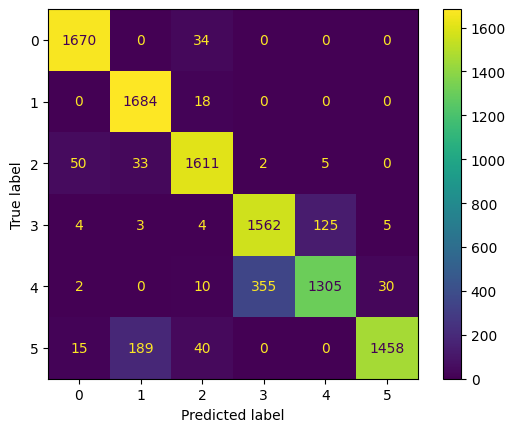

In [115]:
disp.plot()

In [116]:
print(classification_report(y_validation_inverse, classes_x))

              precision    recall  f1-score   support

           0       0.96      0.98      0.97      1704
           1       0.88      0.99      0.93      1702
           2       0.94      0.95      0.94      1701
           3       0.81      0.92      0.86      1703
           4       0.91      0.77      0.83      1702
           5       0.98      0.86      0.91      1702

    accuracy                           0.91     10214
   macro avg       0.91      0.91      0.91     10214
weighted avg       0.91      0.91      0.91     10214



In [117]:
print(segments_test)

[[[ 4.97275686e+00 -1.58316582e-01  6.69673157e+00  3.14944088e-01
   -1.02227652e+00 -3.09961587e-01]
  [ 3.25372005e+00 -1.91835418e-01  6.10775805e+00  3.87382090e-01
   -6.18541241e-01 -4.89718020e-02]
  [ 2.80121589e+00 -1.55922383e-01  5.99762487e+00  7.09985420e-02
   -2.09479719e-01 -1.95978299e-01]
  ...
  [ 7.78354979e+00  9.27753188e-03 -2.22645783e+00 -1.22663522e+00
    3.00887406e-01 -8.98014963e-01]
  [ 1.07667246e+01 -2.13592720e+00 -3.58980626e-01 -1.22770047e+00
   -7.36680150e-01 -3.91058278e+00]
  [ 1.76620255e+01 -2.97389770e+00 -2.58424133e-01 -7.20634580e-01
   -1.95427740e+00 -6.35110331e+00]]

 [[ 1.51337490e+01 -3.26838470e+00 -2.56029934e-01  1.16275287e+00
   -1.16811228e+00 -6.79957962e+00]
  [ 9.21767616e+00 -8.04751039e-01 -8.71339798e-01  2.36011004e+00
   -1.30659664e+00 -5.71087933e+00]
  [ 8.88967133e+00 -2.42113650e-01  1.50984347e-01  2.57422829e+00
   -1.79874873e+00 -3.72309613e+00]
  ...
  [ 1.25432224e+01 -7.16165602e-01 -8.40215147e-01  2.22372

In [118]:
print(labels_test_categorical.shape)

(511, 6)


In [119]:
print(labels_test_categorical)

[[1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]]


In [120]:
loss_test, accuracy_test = best_model.evaluate(segments_test, labels_test_categorical)

16/16 [==============================] - 2s 120ms/step - loss: 0.5864 - accuracy: 0.8885


In [121]:
predictions_test = best_model.predict(segments_test)

16/16 [==============================] - 2s 119ms/step


In [122]:
print(predictions_test)

[[9.9965596e-01 6.7735864e-06 2.7963464e-04 1.2542075e-05 4.0181669e-05
  4.8973238e-06]
 [9.9981171e-01 3.7799482e-06 1.6709047e-04 7.0693663e-06 9.3731269e-06
  9.7220436e-07]
 [9.9985635e-01 2.2392417e-06 1.2586921e-04 7.1470781e-06 6.5533009e-06
  1.8292949e-06]
 ...
 [4.0190880e-05 4.3284474e-03 1.4805011e-03 9.8463206e-04 2.2557676e-04
  9.9294066e-01]
 [3.4384797e-07 9.7251999e-05 4.3791097e-06 2.1928722e-06 3.3266049e-05
  9.9986255e-01]
 [2.0493380e-05 7.1368221e-04 4.9597624e-04 6.4055924e-04 2.2551675e-04
  9.9790370e-01]]


In [123]:
classes_x_test=np.argmax(predictions_test,axis=1)

In [124]:
print(classes_x_test)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 0 2 0 2 0 0 0 2
 0 2 0 0 2 0 2 2 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 5 5 5 4 4 2 5 5 5 5 5 5 5 5 5 5 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5
 5 5 5 5 5 5 5 5 5 5 5 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5
 5 5 0 2 2 0 0 2 2 0 0 2 0 0 0 0 0 0 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4
 3 3 3 3 3 3 3 3 3 3 3 3 

In [125]:
labels_test_argmax = np.argmax(labels_test_categorical,axis=1)

In [126]:
print(labels_test_argmax)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5
 5 5 5 5 5 5 5 5 5 5 5 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5
 5 5 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 

In [127]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm_test = confusion_matrix(labels_test_argmax, classes_x_test)

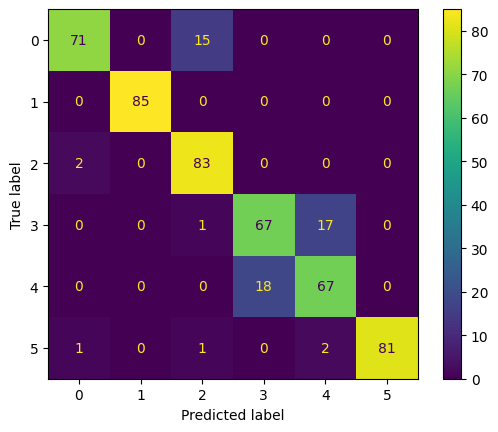

In [128]:
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
disp_test.plot()

In [129]:
print(classification_report(labels_test_argmax, classes_x_test))

              precision    recall  f1-score   support

           0       0.96      0.83      0.89        86
           1       1.00      1.00      1.00        85
           2       0.83      0.98      0.90        85
           3       0.79      0.79      0.79        85
           4       0.78      0.79      0.78        85
           5       1.00      0.95      0.98        85

    accuracy                           0.89       511
   macro avg       0.89      0.89      0.89       511
weighted avg       0.89      0.89      0.89       511



In [130]:
best_model.save(WORKDIR+"/Model/best_models_saved")

INFO:tensorflow:Assets written to: C:/Users/thewr/git/LSTM_giroscopio_acelerometro.git//Model/best_models_saved\assets


INFO:tensorflow:Assets written to: C:/Users/thewr/git/LSTM_giroscopio_acelerometro.git//Model/best_models_saved\assets
